## verifier notre environnement

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU name:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU available: True
GPU name: Tesla T4


## verifier notre dataset


In [3]:

from pathlib import Path

DATA_DIR = Path("../data/raw/cifar-10-batches-py")

print("Dataset folder exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    print("Files found:")
    for file in sorted(DATA_DIR.iterdir()):
        print(file.name)

Dataset folder exists: True
Files found:
batches.meta
data_batch_1
data_batch_2
data_batch_3
data_batch_4
data_batch_5
readme.html
test_batch


In [4]:
import tensorflow as tf
from tensorflow.keras import datasets, layers,models
import matplotlib.pyplot as plt

In [5]:

from pathlib import Path

DATA_DIR = Path("../data/raw/cifar-10-batches-py")

for name in [
    "data_batch_1",
    "data_batch_2",
    "data_batch_3",
    "data_batch_4",
    "data_batch_5",
    "test_batch",
]:
    file_path = DATA_DIR / name

    if file_path.exists():
        size_mb = file_path.stat().st_size / (1024 * 1024)
        print(f"{name}: {size_mb:.2f} MB")
    else:
        print(f"{name}: FILE MISSING")


data_batch_1: 29.60 MB
data_batch_2: 29.60 MB
data_batch_3: 29.60 MB
data_batch_4: 29.60 MB
data_batch_5: 29.60 MB
test_batch: 29.60 MB


In [6]:

import numpy as np
import pickle
from pathlib import Path

DATA_DIR = Path("../data/raw/cifar-10-batches-py")

# Function to read a CIFAR-10 batch
def load_batch(file_path):
    with open(file_path, "rb") as file:
        batch = pickle.load(file, encoding="bytes")

    images = batch[b"data"]
    labels = np.array(batch[b"labels"])

    images = images.reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)

    return images, labels

# Load the five training batches
train_images_list = []
train_labels_list = []

for i in range(1, 6):
    images_batch, labels_batch = load_batch(
        DATA_DIR / f"data_batch_{i}"
    )
    train_images_list.append(images_batch)
    train_labels_list.append(labels_batch)

train_images = np.concatenate(train_images_list, axis=0)
train_labels = np.concatenate(train_labels_list, axis=0)

# Load the test batch
test_images, test_labels = load_batch(DATA_DIR / "test_batch")

print("Training images:", train_images.shape)
print("Training labels:", train_labels.shape)
print("Test images:", test_images.shape)
print("Test labels:", test_labels.shape)


Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)


In [7]:
#Normalize pixel values to be between 0 and 1
train_images,test_images=train_images/255.0,test_images/255.0

## verify the data

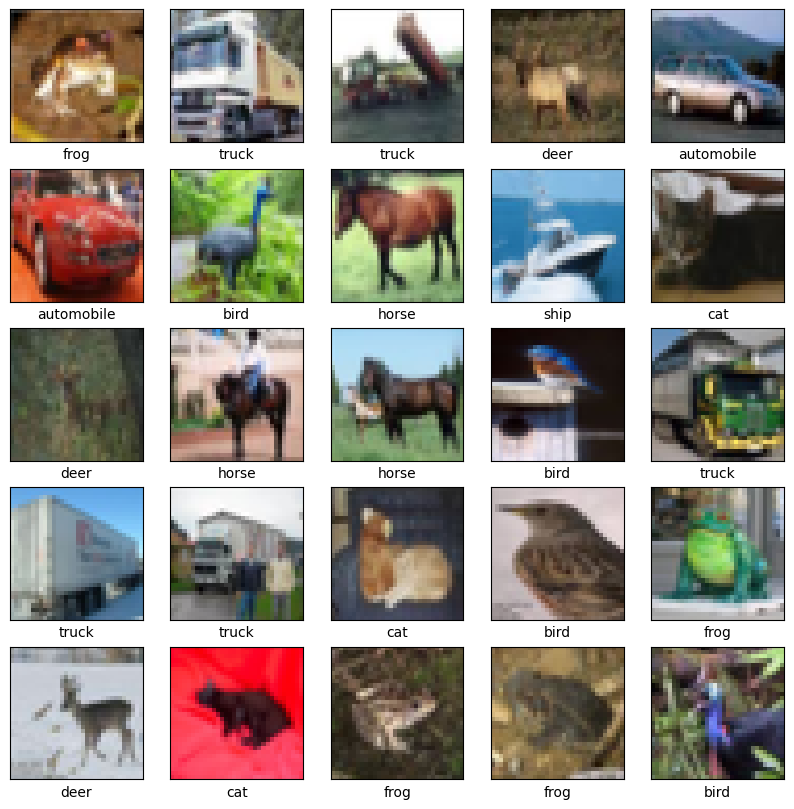

In [8]:
class_name=["airplane","automobile","bird","cat","deer",
            "dog","frog","horse","ship","truck"]
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(train_images[i])
  plt.xlabel(class_name[train_labels[i]])
plt.show()

## Split the dataset into training, validation and test sets

In [9]:
from sklearn.model_selection import train_test_split

# Split the original training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    train_images, train_labels, test_size=0.10, random_state=42 , stratify=train_labels
)

In [10]:
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", test_images.shape, test_labels.shape)

Training set: (45000, 32, 32, 3) (45000,)
Validation set: (5000, 32, 32, 3) (5000,)
Test set: (10000, 32, 32, 3) (10000,)


In [11]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [12]:
print("Minimum pixel value:", test_images.min())
print("Maximum pixel value:", test_images.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [13]:
test_labels

array([3, 8, 8, ..., 5, 1, 7])

## encodage OHE

In [14]:
from tensorflow.keras.utils import to_categorical

# Convert labels to one-hot encoding
num_classes = 10
y_train = to_categorical(y_train, num_classes)
y_val = to_categorical(y_val, num_classes)
y_test = to_categorical(test_labels, num_classes)

In [15]:
X_test=test_images

In [16]:
y_test

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.]])

In [17]:

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (45000, 32, 32, 3)
y_train: (45000, 10)
X_val: (5000, 32, 32, 3)
y_val: (5000, 10)
X_test: (10000, 32, 32, 3)
y_test: (10000, 10)


## MLP Model

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
## definir le MLP pour la classification dimages
model_mlp=keras.Sequential([layers.Flatten(input_shape=(32,32,3)),layers.Dense(128,activation="relu"),layers.Dense(10,activation="softmax")])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
## compiler el modele avec une fonction de perte , un optimiseur et des metriques
model_mlp.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [ ]:
model_mlp.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 394,634 (1.51 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
epochs = 30
batch_size = 128

history_mlp = model_mlp.fit(
    X_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.3035 - loss: 1.9465 - val_accuracy: 0.3458 - val_loss: 1.8430
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3655 - loss: 1.8001 - val_accuracy: 0.3740 - val_loss: 1.7701
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3837 - loss: 1.7455 - val_accuracy: 0.3952 - val_loss: 1.7204
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3959 - loss: 1.7080 - val_accuracy: 0.3890 - val_loss: 1.7147
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4062 - loss: 1.6773 - val_accuracy: 0.3932 - val_loss: 1.7014
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4134 - loss: 1.6558 - val_accuracy: 0.4136 - val_loss: 1.6671
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4157 - loss: 1.6411 - val_accuracy: 0.4116 - val_loss: 1.6475
Epoch 8/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4246 - loss: 1.6208 - val_accuracy: 0

In [ ]:
import numpy as np

best_epoch = np.argmin(history_mlp.history["val_loss"]) + 1
best_val_loss = min(history_mlp.history["val_loss"])
best_val_accuracy = history_mlp.history["val_accuracy"][best_epoch - 1]

print("Meilleure époque :", best_epoch)
print(f"Meilleure val_loss : {best_val_loss:.4f}")
print(f"Accuracy de validation à cette époque : {best_val_accuracy:.2%}")

Meilleure époque : 9
Meilleure val_loss : 1.6161
Accuracy de validation à cette époque : 42.44%


## Visualiser les courbes d'apprentissage

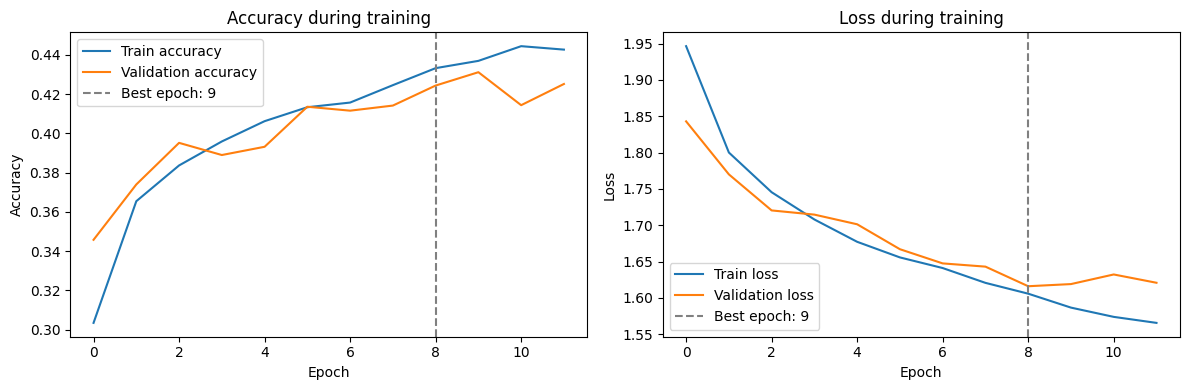

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_mlp.history["accuracy"], label="Train accuracy")
plt.plot(history_mlp.history["val_accuracy"], label="Validation accuracy")
plt.axvline(8, color="gray", linestyle="--", label="Best epoch: 9")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_mlp.history["loss"], label="Train loss")
plt.plot(history_mlp.history["val_loss"], label="Validation loss")
plt.axvline(8, color="gray", linestyle="--", label="Best epoch: 9")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.legend()

plt.tight_layout()
plt.show()

L'analyse des courbes montre que le modèle converge correctement sur le jeu d'entraînement. Toutefois, la validation accuracy stagne autour de 48 % tandis que la validation loss augmente légèrement au fil des epochs. Cela indique un début de surapprentissage. Cette limitation est attendue avec un MLP sur CIFAR-10, car il ne tient pas compte de la structure spatiale des images. La prochaine amélioration naturelle consiste à utiliser un réseau convolutif (CNN), mieux adapté aux tâches de classification d'images

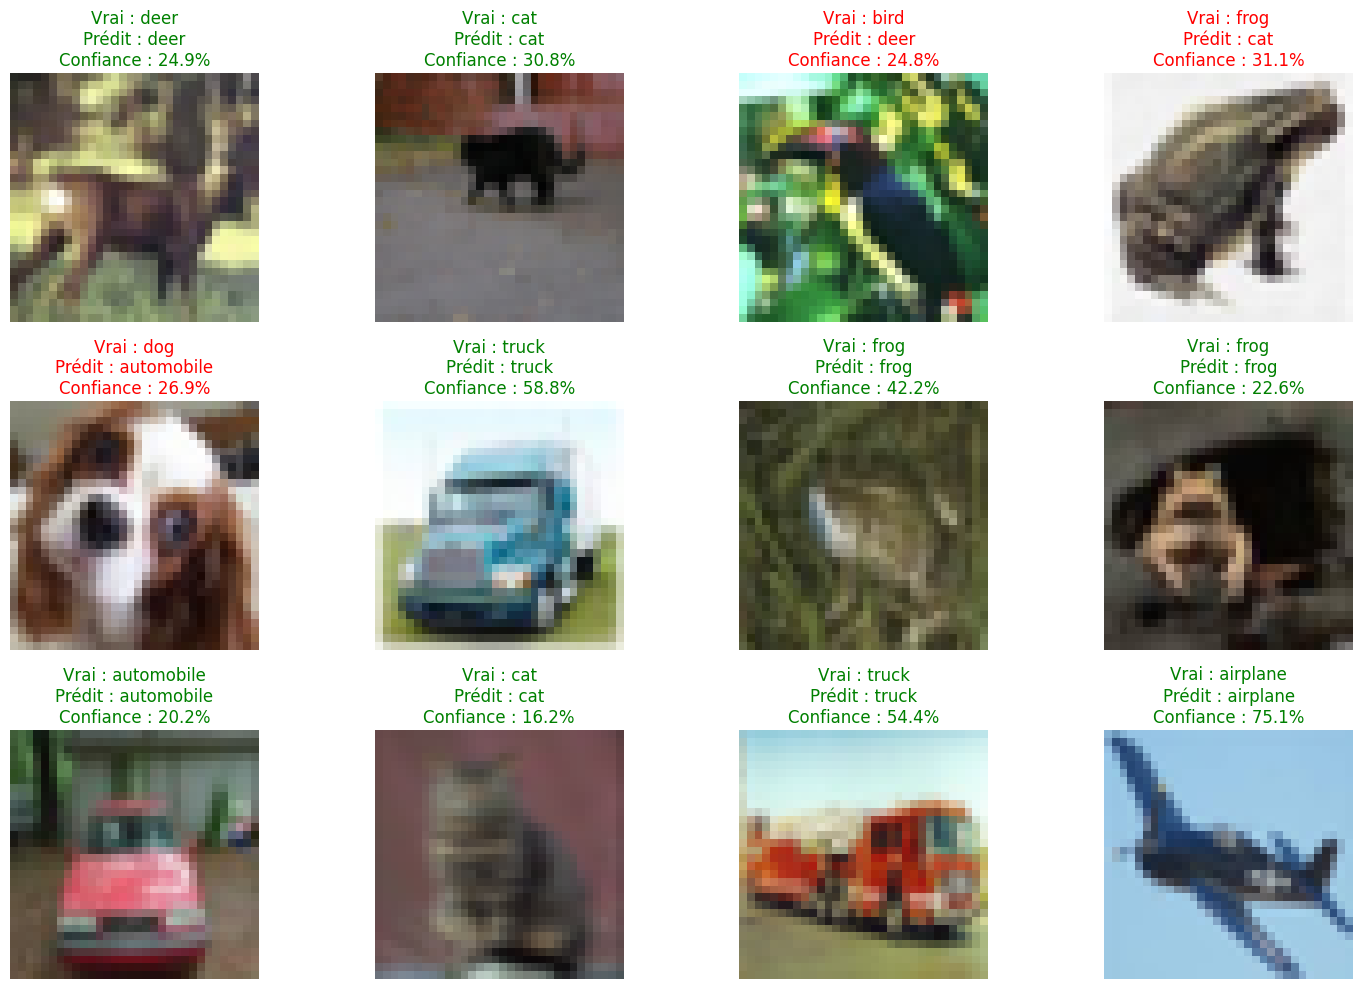

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Sélectionner 12 images du jeu de test
num_images = 12
indices = np.random.choice(len(X_test), num_images, replace=False)

images = X_test[indices]
true_labels = np.argmax(y_test[indices], axis=1)

# 2. Prédire les probabilités pour chaque classe
predictions = model_mlp.predict(images, verbose=0)

# 3. Récupérer la classe prédite et sa probabilité
predicted_labels = np.argmax(predictions, axis=1)
confidence = np.max(predictions, axis=1)

# 4. Afficher les images et les résultats
plt.figure(figsize=(15, 10))

for i in range(num_images):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i])

    true_name = class_name[true_labels[i]]
    predicted_name = class_name[predicted_labels[i]]

    if true_labels[i] == predicted_labels[i]:
        color = "green"
    else:
        color = "red"

    plt.title(
        f"Vrai : {true_name}\n"
        f"Prédit : {predicted_name}\n"
        f"Confiance : {confidence[i]:.1%}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## évaluation du MLP sur le jeu de test

In [ ]:
test_loss, test_accuracy = model_mlp.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4336 - loss: 1.5975
Test loss: 1.5975
Test accuracy: 43.36%


## Sauvegarder le modèle MLP

In [ ]:
# Sauvegarder le modèle MLP entraîné
model_mlp.save("../models/mlp/model_mlp.keras")

print("Modèle MLP sauvegardé avec succès !")

Modèle MLP sauvegardé avec succès !


In [ ]:
##Sauvegarder les performances et l'historique avec Joblib
import joblib
import numpy as np

# Identifier la meilleure époque
best_epoch_mlp = np.argmin(
    history_mlp.history["val_loss"]
) + 1

# Évaluer le modèle sur le jeu de test
test_loss_mlp, test_accuracy_mlp = model_mlp.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Préparer les résultats
results_mlp = {
    "model_name": "MLP",
    "best_epoch": int(best_epoch_mlp),
    "train_accuracy_best_epoch": float(
        history_mlp.history["accuracy"][best_epoch_mlp - 1]
    ),
    "val_accuracy_best_epoch": float(
        history_mlp.history["val_accuracy"][best_epoch_mlp - 1]
    ),
    "best_val_loss": float(
        history_mlp.history["val_loss"][best_epoch_mlp - 1]
    ),
    "test_accuracy": float(test_accuracy_mlp),
    "test_loss": float(test_loss_mlp),
    "history": history_mlp.history
}

# Enregistrer les résultats
joblib.dump(results_mlp, "../results/metrics/mlp/results_mlp.joblib")

print("Résultats MLP sauvegardés !")
print("Meilleure époque :", best_epoch_mlp)
print(f"Train accuracy : {results_mlp['train_accuracy_best_epoch']:.2%}")
print(f"Validation accuracy : {results_mlp['val_accuracy_best_epoch']:.2%}")
print(f"Test accuracy : {test_accuracy_mlp:.2%}")

Résultats MLP sauvegardés !
Meilleure époque : 9
Train accuracy : 43.33%
Validation accuracy : 42.44%
Test accuracy : 43.36%


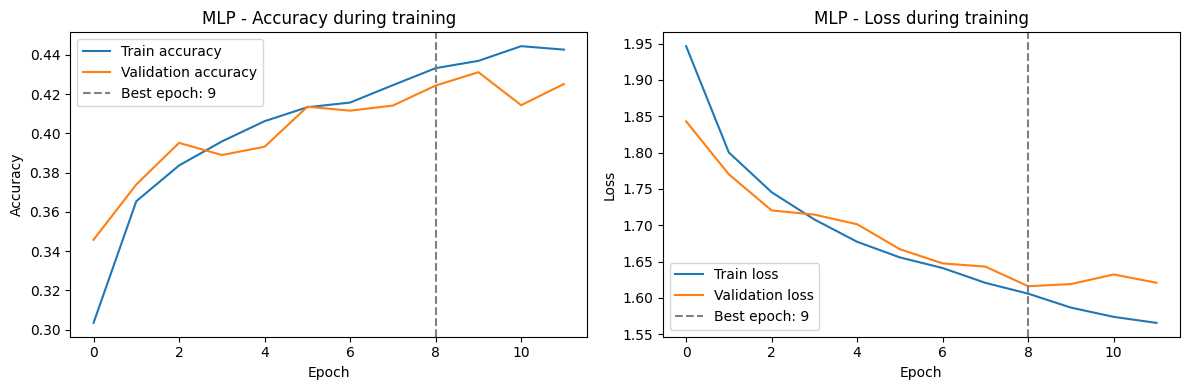

Courbes sauvegardées dans curves_mlp.png


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Courbe d'accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_mlp.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history_mlp.history["val_accuracy"],
    label="Validation accuracy"
)

plt.axvline(
    best_epoch_mlp - 1,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch_mlp}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP - Accuracy during training")
plt.legend()

# Courbe de loss
plt.subplot(1, 2, 2)

plt.plot(history_mlp.history["loss"], label="Train loss")
plt.plot(history_mlp.history["val_loss"], label="Validation loss")

plt.axvline(
    best_epoch_mlp - 1,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch_mlp}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP - Loss during training")
plt.legend()

plt.tight_layout()

# Sauvegarder avant plt.show()
plt.savefig("../results/figures/mlp/curves_mlp.png", dpi=300, bbox_inches="tight")

plt.show()

print("Courbes sauvegardées dans results/figures/mlp/curves_mlp.png")

In [ ]:
from google.colab import files

files.download("../models/mlp/model_mlp.keras")
files.download("../results/metrics/mlp/results_mlp.joblib")
files.download("../results/figures/mlp/curves_mlp.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Le modèle apprend quelque chose : avec 10 classes équilibrées, une classification aléatoire uniforme ferait environ 10 % d'accuracy. Notre MLP atteint 45,25 %.



La performance reste limitée : plus de la moitié des images ne sont pas correctement classées.



La généralisation semble raisonnable : la test accuracy de 45,25 % est proche des valeurs de validation observées. Il faut cependant comparer les métriques issues de la même exécution pour quantifier précisément l'écart.

## Architecture A - CNN Modèle de référence

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [ ]:
model_cnn=Sequential()
model_cnn.add(Conv2D(32,kernel_size=(3,3),padding="same",activation="relu",input_shape=(32,32,3)))
model_cnn.add(MaxPooling2D(pool_size=(2,2)))
model_cnn.add(Conv2D(64,kernel_size=(3,3),padding="same",activation="relu"))
model_cnn.add(MaxPooling2D(pool_size=(2,2)))
model_cnn.add(Flatten())
model_cnn.add(Dense(128,activation="relu"))
model_cnn.add(Dropout(0.2))
model_cnn.add(Dense(10,activation="softmax"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model_cnn.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [ ]:
model_cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Relancer l'entraînement avec le callback
from tensorflow import keras

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
epochs = 30
batch_size = 128

history_cnn = model_cnn.fit(
    X_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.4043 - loss: 1.6427 - val_accuracy: 0.5398 - val_loss: 1.3074
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5395 - loss: 1.2871 - val_accuracy: 0.6016 - val_loss: 1.1422
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5942 - loss: 1.1359 - val_accuracy: 0.6472 - val_loss: 1.0224
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6312 - loss: 1.0446 - val_accuracy: 0.6556 - val_loss: 0.9845
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6571 - loss: 0.9723 - val_accuracy: 0.6826 - val_loss: 0.9172
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6844 - loss: 0.9011 - val_accuracy: 0.6894 - val_loss: 0.8935
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7004 - loss: 0.8540 - val_accuracy: 0.6820 - val_loss: 0.9173
Epoch 8/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7144 - loss: 0.8135 - val_accuracy: 

In [ ]:
#Identifier la meilleure époque
import numpy as np

best_epoch = np.argmin(history_cnn.history["val_loss"]) + 1
best_val_loss = min(history_cnn.history["val_loss"])
best_val_accuracy = history_cnn.history["val_accuracy"][best_epoch - 1]

print("Meilleure époque :", best_epoch)
print(f"Meilleure val_loss : {best_val_loss:.4f}")
print(f"Accuracy de validation à cette époque : {best_val_accuracy:.2%}")

Meilleure époque : 15
Meilleure val_loss : 0.8235
Accuracy de validation à cette époque : 72.26%


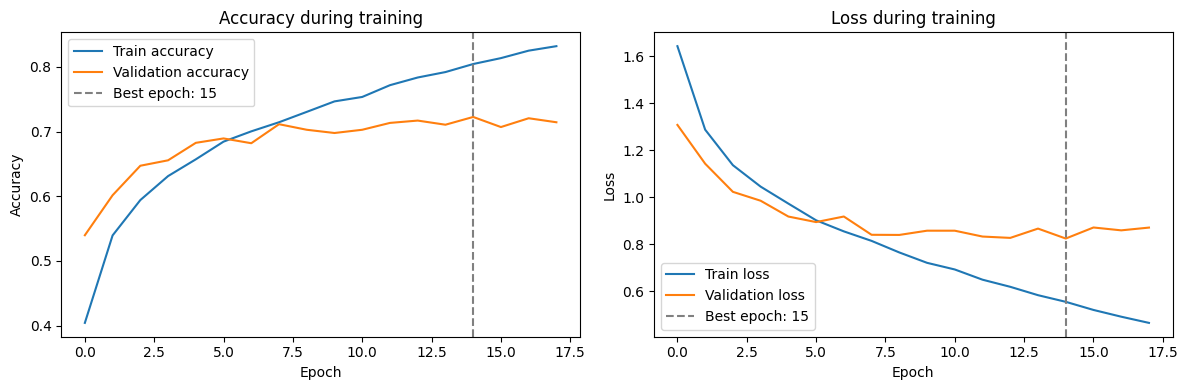

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Train accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation accuracy")
plt.axvline(14, color="gray", linestyle="--", label="Best epoch: 15")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Train loss")
plt.plot(history_cnn.history["val_loss"], label="Validation loss")
plt.axvline(14, color="gray", linestyle="--", label="Best epoch: 15")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.legend()

plt.tight_layout()
plt.show()

Le CNN apprend efficacement les caractéristiques visuelles des images CIFAR-10. Les courbes d'accuracy montrent une progression régulière aussi bien sur l'entraînement que sur la validation, jusqu'à atteindre près de 70 % de précision. Parallèlement, les courbes de loss diminuent continuellement, ce qui indique une convergence stable. Aucun signe important de surapprentissage n'est observé. Les performances sont nettement supérieures à celles obtenues avec le MLP, confirmant que les réseaux convolutifs sont mieux adaptés à la classification d'images puisqu'ils exploitent les relations spatiales entre les pixels.

## Évaluer le CNN sur les images de test

In [ ]:

test_loss_cnn, test_accuracy_cnn = model_cnn.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test loss: {test_loss_cnn:.4f}")
print(f"Test accuracy: {test_accuracy_cnn:.2%}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7226 - loss: 0.8415
Test loss: 0.8415
Test accuracy: 72.26%


## Sauvegarder le modèle et ses performances

In [ ]:
import joblib
import numpy as np
from pathlib import Path

# Créer le dossier de sauvegarde
save_dir_a = Path("../results/metrics/cnn_a")
model_dir_a = Path("../models/cnn_a")
save_dir_a.mkdir(parents=True, exist_ok=True)
model_dir_a.mkdir(parents=True, exist_ok=True)

# 1. Sauvegarder le modèle entraîné
model_cnn.save(model_dir_a / "cnn_a_cifar10.keras")

# 2. Sauvegarder l'historique d'entraînement
joblib.dump(
    history_cnn.history,
    save_dir_a / "history_cnn_a.joblib"
)

# 3. Identifier la meilleure époque
best_epoch_a = int(
    np.argmin(history_cnn.history["val_loss"]) + 1
)

# 4. Rassembler les métriques
results_cnn_a = {
    "model": "CNN A",
    "best_epoch": best_epoch_a,
    "best_val_loss": float(
        min(history_cnn.history["val_loss"])
    ),
    "best_val_accuracy": float(
        history_cnn.history["val_accuracy"][best_epoch_a - 1]
    ),
    "test_loss": float(test_loss_cnn),
    "test_accuracy": float(test_accuracy_cnn)
}

# 5. Sauvegarder les résultats
joblib.dump(
    results_cnn_a,
    save_dir_a / "metrics_cnn_a.joblib"
)

print("Sauvegarde de CNN A terminée !")
print(results_cnn_a)

Sauvegarde de CNN A terminée !
{'model': 'CNN A', 'best_epoch': 15, 'best_val_loss': 0.8235354423522949, 'best_val_accuracy': 0.722599983215332, 'test_loss': 0.84148770570755, 'test_accuracy': 0.722599983215332}


## Sauvegarder les courbes Accuracy et Loss

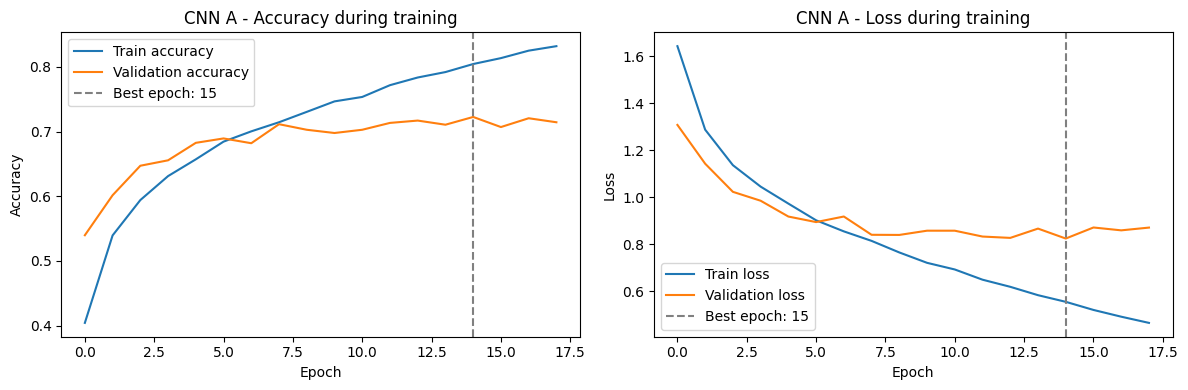

Courbes sauvegardées !


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Train accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation accuracy")
plt.axvline(
    best_epoch_a - 1,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch_a}"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN A - Accuracy during training")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Train loss")
plt.plot(history_cnn.history["val_loss"], label="Validation loss")
plt.axvline(
    best_epoch_a - 1,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch_a}"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN A - Loss during training")
plt.legend()

plt.tight_layout()

# Sauvegarder les graphiques
plt.savefig(
    Path("../results/figures/cnn_a") / "cnn_a_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Courbes sauvegardées !")

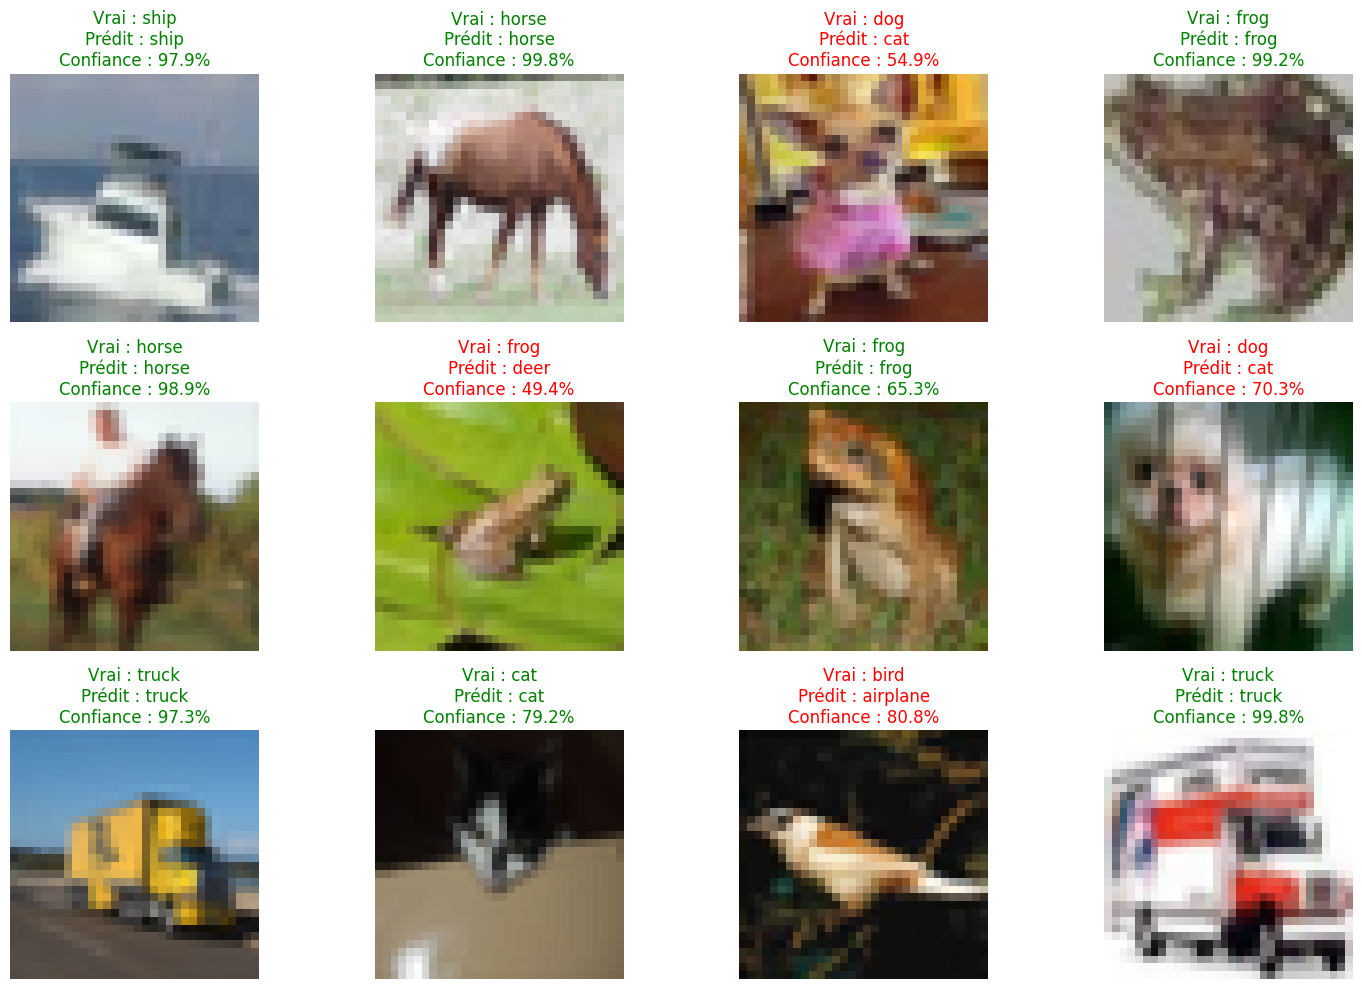

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Sélectionner 12 images du jeu de test
num_images = 12
indices = np.random.choice(len(X_test), num_images, replace=False)

images = X_test[indices]
true_labels = np.argmax(y_test[indices], axis=1)

# 2. Prédire les probabilités pour chaque classe
predictions = model_cnn.predict(images, verbose=0)

# 3. Récupérer la classe prédite et sa probabilité
predicted_labels = np.argmax(predictions, axis=1)
confidence = np.max(predictions, axis=1)

# 4. Afficher les images et les résultats
plt.figure(figsize=(15, 10))

for i in range(num_images):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i])

    true_name = class_name[true_labels[i]]
    predicted_name = class_name[predicted_labels[i]]

    if true_labels[i] == predicted_labels[i]:
        color = "green"
    else:
        color = "red"

    plt.title(
        f"Vrai : {true_name}\n"
        f"Prédit : {predicted_name}\n"
        f"Confiance : {confidence[i]:.1%}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

correct = np.sum(predicted_labels == true_labels)

print(f"Images correctement classées : {correct}/{num_images}")
print(f"Accuracy sur ces images : {correct / num_images:.2%}")


Images correctement classées : 8/12
Accuracy sur ces images : 66.67%


## Architecture B — CNN plus profond

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [ ]:
model_cnn_b=Sequential()
##bloc 1
model_cnn_b.add(Conv2D(32,kernel_size=(3,3),padding="same",activation="relu",input_shape=(32,32,3)))
model_cnn_b.add(Conv2D(32, (3, 3), padding="same", activation="relu",input_shape=(32,32,3)))
model_cnn_b.add(MaxPooling2D(pool_size=(2,2)))
## bloc 2
model_cnn_b.add(Conv2D(64,kernel_size=(3,3),padding="same",activation="relu",input_shape=(32,32,3)))
model_cnn_b.add(Conv2D(64, (3, 3), padding="same", activation="relu",input_shape=(32,32,3)))
model_cnn_b.add(MaxPooling2D(pool_size=(2,2)))
##bloc 3
model_cnn_b.add(Conv2D(128, (3, 3), padding="same", activation="relu",input_shape=(32,32,3)))
model_cnn_b.add(MaxPooling2D(pool_size=(2,2)))
# Classification
model_cnn_b.add(Flatten())
model_cnn_b.add(Dense(128,activation="relu"))
model_cnn_b.add(Dropout(0.5))
model_cnn_b.add(Dense(10,activation="softmax"))

In [ ]:
model_cnn_b.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,986 (1.54 MB)

 Trainable params: 402,986 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model_cnn_b.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
#Relancer l'entraînement avec le callback
from tensorflow import keras

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
epochs = 30
batch_size = 128

history_cnn_b = model_cnn_b.fit(
    X_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.3528 - loss: 1.7419 - val_accuracy: 0.5108 - val_loss: 1.3643
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.5223 - loss: 1.3282 - val_accuracy: 0.6210 - val_loss: 1.0909
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6114 - loss: 1.1104 - val_accuracy: 0.6452 - val_loss: 0.9849
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6626 - loss: 0.9689 - val_accuracy: 0.6928 - val_loss: 0.8624
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6987 - loss: 0.8728 - val_accuracy: 0.6958 - val_loss: 0.8612
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.7275 - loss: 0.7887 - val_accuracy: 0.7362 - val_loss: 0.7692
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.7518 - loss: 0.7208 - val_accuracy: 0.7496 - val_loss: 0.7167
Epoch 8/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.7687 - loss: 0.6588 - val_acc

In [ ]:
#Identifier la meilleure époque
import numpy as np

best_epoch = np.argmin(history_cnn_b.history["val_loss"]) + 1
best_val_loss = min(history_cnn_b.history["val_loss"])
best_val_accuracy = history_cnn_b.history["val_accuracy"][best_epoch - 1]

print("Meilleure époque :", best_epoch)
print(f"Meilleure val_loss : {best_val_loss:.4f}")
print(f"Accuracy de validation à cette époque : {best_val_accuracy:.2%}")

Meilleure époque : 12
Meilleure val_loss : 0.6735
Accuracy de validation à cette époque : 77.70%


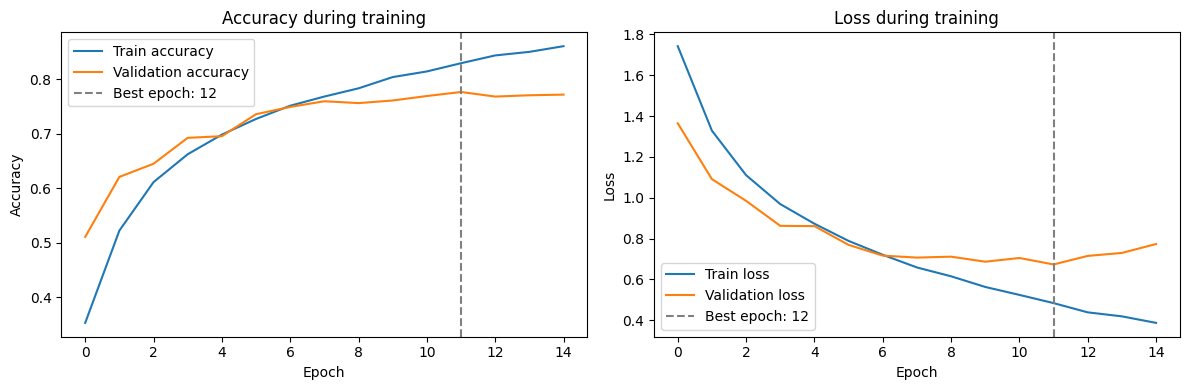

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_cnn_b.history["accuracy"], label="Train accuracy")
plt.plot(history_cnn_b.history["val_accuracy"], label="Validation accuracy")
plt.axvline(11, color="gray", linestyle="--", label="Best epoch: 12")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn_b.history["loss"], label="Train loss")
plt.plot(history_cnn_b.history["val_loss"], label="Validation loss")
plt.axvline(11, color="gray", linestyle="--", label="Best epoch: 12")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.legend()

plt.tight_layout()
plt.show()

## évaluer le CNN B sur le jeu de test

In [ ]:

test_loss_cnn_b, test_accuracy_cnn_b = model_cnn_b.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"CNN B - Test loss: {test_loss_cnn_b:.4f}")
print(f"CNN B - Test accuracy: {test_accuracy_cnn_b:.2%}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7733 - loss: 0.6917
CNN B - Test loss: 0.6917
CNN B - Test accuracy: 77.33%


In [ ]:
import joblib
import numpy as np
from pathlib import Path

# Créer le dossier de résultats
save_dir_b = Path("../results/metrics/cnn_b")
model_dir_b = Path("../models/cnn_b")
save_dir_b.mkdir(parents=True, exist_ok=True)
model_dir_b.mkdir(parents=True, exist_ok=True)

# 1. Sauvegarder le modèle complet
model_cnn_b.save(model_dir_b / "cnn_bifar10.keras")

# 2. Sauvegarder l'historique d'entraînement
joblib.dump(
    history_cnn_b.history,
    save_dir_b / "history_cnn_b.joblib"
)

# 3. Calculer les meilleures métriques
best_epoch_b = int(
    np.argmin(history_cnn_b.history["val_loss"]) + 1
)

results_cnn_b = {
    "model": "CNN B",
    "best_epoch": best_epoch_b,
    "best_val_loss": float(
        min(history_cnn_b.history["val_loss"])
    ),
    "best_val_accuracy": float(
        history_cnn_b.history["val_accuracy"][best_epoch_b - 1]
    ),
    "test_loss": float(test_loss_cnn_b),
    "test_accuracy": float(test_accuracy_cnn_b)
}

# 4. Sauvegarder les résultats
joblib.dump(
    results_cnn_b,
    save_dir_b / "metrics_cnn_b.joblib"
)

print("Sauvegarde de CNN B terminée !")
print(results_cnn_b)

Sauvegarde de CNN B terminée !
{'model': 'CNN B', 'best_epoch': 12, 'best_val_loss': 0.6734973192214966, 'best_val_accuracy': 0.7770000100135803, 'test_loss': 0.6917048096656799, 'test_accuracy': 0.7732999920845032}


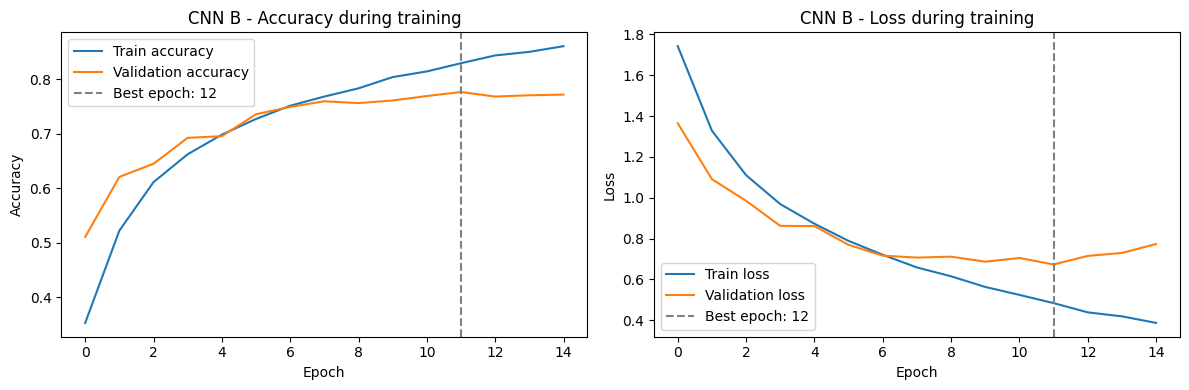

Courbes sauvegardées dans : results_cnn_b/cnn_b_training_curves.png


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_cnn_b.history["accuracy"], label="Train accuracy")
plt.plot(history_cnn_b.history["val_accuracy"], label="Validation accuracy")
plt.axvline(
    best_epoch_b - 1,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch_b}"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN B - Accuracy during training")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn_b.history["loss"], label="Train loss")
plt.plot(history_cnn_b.history["val_loss"], label="Validation loss")
plt.axvline(
    best_epoch_b - 1,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch_b}"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN B - Loss during training")
plt.legend()

plt.tight_layout()

# Sauvegarder les courbes
plt.savefig(
    Path("../results/figures/cnn_b") / "cnn_b_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Courbes sauvegardées dans :", Path("../results/figures/cnn_b") / "cnn_b_training_curves.png")

Comparaison de nos architectures :                                 
Métrique	                      |      CNN A         |         	CNN B     
__________________________________________________________________________                                   |                    |
Paramètres entraînables         |     545 098        |	         402 986
Meilleure accuracy validation   |      68,46 %       |        	77,98 %
Accuracy test                   |    	67.41%	       |         77,36 %

C'est particulièrement intéressant : CNN B obtient de meilleurs résultats avec moins de paramètres. Ses couches convolutives supplémentaires permettent d'apprendre des représentations plus riches, tandis que le troisième Max Pooling réduit la taille du vecteur transmis aux couches denses.

## Architecture C — CNN régularisé

CNN C avec Batch Normalization et augmentation de données

In [ ]:

from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )
], name="data_augmentation")

model_cnn_c = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Augmentation : active uniquement pendant l'entraînement
    data_augmentation,

    # Bloc 1
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # Bloc 2
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # Bloc 3
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Classification
    layers.Flatten(),
    layers.Dense(128, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])

model_cnn_c.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 404,330 (1.54 MB)

 Trainable params: 403,434 (1.54 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
model_cnn_c.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
#Relancer l'entraînement avec le callback
from tensorflow import keras

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
epochs = 30
batch_size = 128

history_cnn_c = model_cnn_c.fit(
    X_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.4600 - loss: 1.4996 - val_accuracy: 0.2794 - val_loss: 2.1365
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6011 - loss: 1.1176 - val_accuracy: 0.6330 - val_loss: 1.0335
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6631 - loss: 0.9524 - val_accuracy: 0.6740 - val_loss: 0.9221
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6993 - loss: 0.8555 - val_accuracy: 0.7164 - val_loss: 0.7933
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7239 - loss: 0.7851 - val_accuracy: 0.6970 - val_loss: 0.8859
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7372 - loss: 0.7426 - val_accuracy: 0.7688 - val_loss: 0.6418
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7560 - loss: 0.7001 - val_accuracy: 0.7796 - val_loss: 0.6404
Epoch 8/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7674 - loss: 0.6654 - 

In [ ]:
#Identifier la meilleure époque
import numpy as np

best_epoch = np.argmin(history_cnn_c.history["val_loss"]) + 1
best_val_loss = min(history_cnn_c.history["val_loss"])
best_val_accuracy = history_cnn_c.history["val_accuracy"][best_epoch - 1]

print("Meilleure époque :", best_epoch)
print(f"Meilleure val_loss : {best_val_loss:.4f}")
print(f"Accuracy de validation à cette époque : {best_val_accuracy:.2%}")

Meilleure époque : 13
Meilleure val_loss : 0.5023
Accuracy de validation à cette époque : 82.54%


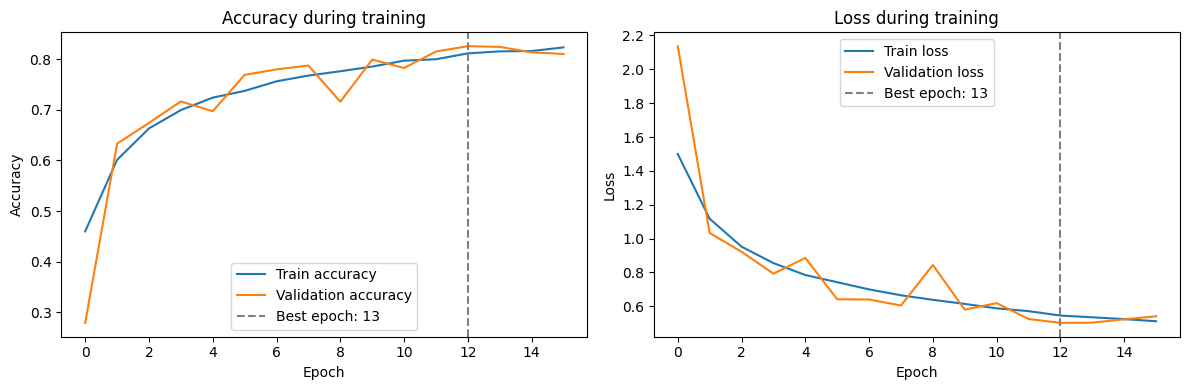

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_cnn_c.history["accuracy"], label="Train accuracy")
plt.plot(history_cnn_c.history["val_accuracy"], label="Validation accuracy")
plt.axvline(12, color="gray", linestyle="--", label="Best epoch: 13")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn_c.history["loss"], label="Train loss")
plt.plot(history_cnn_c.history["val_loss"], label="Validation loss")
plt.axvline(12, color="gray", linestyle="--", label="Best epoch: 13")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.legend()

plt.tight_layout()
plt.show()

## évaluer CNN C sur le jeu de test

In [ ]:
test_loss_c, test_accuracy_c = model_cnn_c.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test loss: {test_loss_c:.4f}")
print(f"Test accuracy: {test_accuracy_c:.2%}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8191 - loss: 0.5242
Test loss: 0.5242
Test accuracy: 81.91%


In [ ]:
%pip install joblib

In [ ]:
import joblib
import numpy as np
from pathlib import Path

# Dossier de sauvegarde
save_dir = Path("../results/metrics/cnn_c")
model_dir = Path("../models/cnn_c")
save_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

# 1. Sauvegarder le modèle entraîné
model_cnn_c.save(model_dir / "cnn_cifar10.keras")

# 2. Sauvegarder l'historique d'entraînement
joblib.dump(
    history_cnn_c.history,
    save_dir / "history_cnn_c.joblib"
)

# 3. Sauvegarder les performances
best_epoch = int(np.argmin(history_cnn_c.history["val_loss"]) + 1)

results = {
    "model": "CNN C",
    "best_epoch": best_epoch,
    "best_val_loss": float(min(history_cnn_c.history["val_loss"])),
    "best_val_accuracy": float(
        history_cnn_c.history["val_accuracy"][best_epoch - 1]
    ),
    "test_loss": float(test_loss_c),
    "test_accuracy": float(test_accuracy_c)
}

joblib.dump(results, save_dir / "metrics_cnn_c.joblib")

print("Sauvegarde terminée !")
print(results)

Sauvegarde terminée !
{'model': 'CNN C', 'best_epoch': 13, 'best_val_loss': 0.5023259520530701, 'best_val_accuracy': 0.8253999948501587, 'test_loss': 0.5241568684577942, 'test_accuracy': 0.819100022315979}


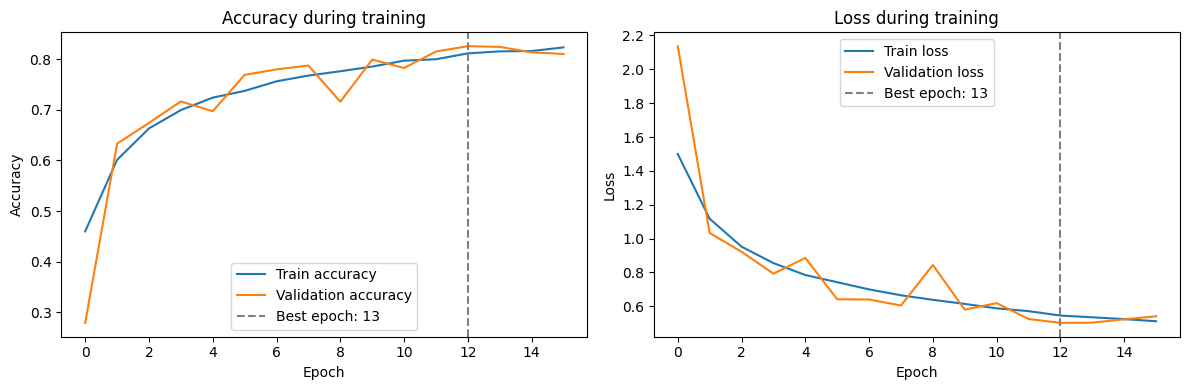

Courbes sauvegardées dans : results_cnn_c/cnn_c_training_curves.png


In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

# Créer un dossier pour les résultats
save_dir = Path("../results/figures/cnn_c")
save_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_cnn_c.history["accuracy"], label="Train accuracy")
plt.plot(history_cnn_c.history["val_accuracy"], label="Validation accuracy")
plt.axvline(12, color="gray", linestyle="--", label="Best epoch: 13")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn_c.history["loss"], label="Train loss")
plt.plot(history_cnn_c.history["val_loss"], label="Validation loss")
plt.axvline(12, color="gray", linestyle="--", label="Best epoch: 13")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.legend()

plt.tight_layout()

# Sauvegarder la figure en haute résolution
plt.savefig(
    save_dir / "cnn_c_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Courbes sauvegardées dans :", save_dir / "cnn_c_training_curves.png")

In [ ]:
from tensorflow import keras

# 1. Charger le MLP
model_mlp = keras.models.load_model(
    "../models/mlp/model_mlp.keras"
)

# 2. Charger CNN A
model_cnn_a = keras.models.load_model(
    "../models/cnn_a/cnn_a_cifar10.keras"
)

# 3. Charger CNN B
model_cnn_b = keras.models.load_model(
    "../models/cnn_b/cnn_bifar10.keras"
)

# 4. Charger CNN C
model_cnn_c = keras.models.load_model(
    "../models/cnn_c/cnn_cifar10.keras"
)

print("Les quatre modèles ont été chargés avec succès !")

Les quatre modèles ont été chargés avec succès !


In [ ]:
models = {
    "MLP": model_mlp,
    "CNN A": model_cnn_a,
    "CNN B": model_cnn_b,
    "CNN C": model_cnn_c
}

for name, model in models.items():
    print(f"\n{name}")
    print("Nombre de paramètres :", model.count_params())
    print("Entrée :", model.input_shape)
    print("Sortie :", model.output_shape)


MLP
Nombre de paramètres : 394634
Entrée : (None, 32, 32, 3)
Sortie : (None, 10)

CNN A
Nombre de paramètres : 545098
Entrée : (None, 32, 32, 3)
Sortie : (None, 10)

CNN B
Nombre de paramètres : 402986
Entrée : (None, 32, 32, 3)
Sortie : (None, 10)

CNN C
Nombre de paramètres : 404330
Entrée : (None, 32, 32, 3)
Sortie : (None, 10)


## comparer les quatre modèles

In [19]:
from tensorflow import keras

# Recharger les modèles sauvegardés sans restaurer leur compilation
model_mlp = keras.models.load_model(
    "../models/mlp/model_mlp.keras", compile=False
)

model_cnn_a = keras.models.load_model(
    "../models/cnn_a/cnn_a_cifar10.keras", compile=False
)

model_cnn_b = keras.models.load_model(
    "../models/cnn_b/cnn_bifar10.keras", compile=False
)

model_cnn_c = keras.models.load_model(
    "../models/cnn_c/cnn_cifar10.keras", compile=False
)

# Recréer la compilation pour des labels OHE
models = {
    "MLP": model_mlp,
    "CNN A": model_cnn_a,
    "CNN B": model_cnn_b,
    "CNN C": model_cnn_c
}

for model in models.values():
    model.compile(
        loss="categorical_crossentropy",
        metrics=["accuracy"],
        run_eagerly=True
    )

print("Modèles rechargés et recompilés.")

Modèles rechargés et recompilés.


In [20]:
import pandas as pd

results = []

for name, model in models.items():
    print(f"Évaluation de {name}...")

    loss, accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    results.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Test Loss": loss,
        "Test Accuracy (%)": accuracy * 100
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Test Accuracy (%)",
        ascending=False
    ).reset_index(drop=True).round(4)
)

Évaluation de MLP...
Évaluation de CNN A...
Évaluation de CNN B...
Évaluation de CNN C...


,Model,Parameters,Test Loss,Test Accuracy (%)
0,CNN C,404330,0.5242,81.91
1,CNN B,402986,0.6917,77.33
2,CNN A,545098,0.8415,72.26
3,MLP,394634,1.5975,43.36


Nombre d'images mal classées : 1809
Nombre total d'images : 10000
Accuracy : 81.91%


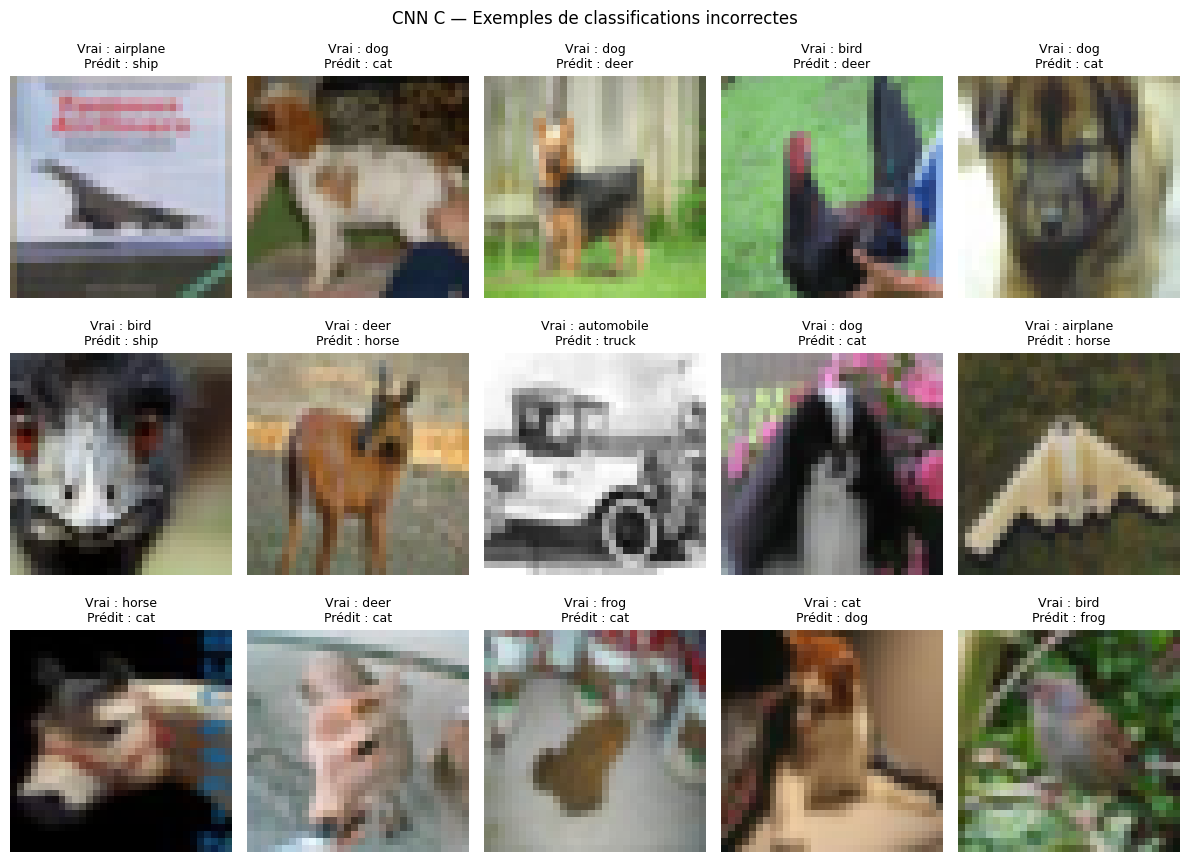

In [21]:
import numpy as np
import matplotlib.pyplot as plt

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Prédictions du CNN C déjà entraîné
y_pred_probs = model_cnn_c.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

# Indices des images mal classées
errors = np.where(y_pred != y_true)[0]

print("Nombre d'images mal classées :", len(errors))
print("Nombre total d'images :", len(y_true))
print(f"Accuracy : {np.mean(y_pred == y_true) * 100:.2f}%")

# Afficher jusqu'à 15 erreurs
n = min(15, len(errors))

plt.figure(figsize=(12, 9))

for i, idx in enumerate(errors[:n]):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[idx])
    plt.title(
        f"Vrai : {class_names[y_true[idx]]}\n"
        f"Prédit : {class_names[y_pred[idx]]}",
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("CNN C — Exemples de classifications incorrectes")
plt.tight_layout()
plt.show()

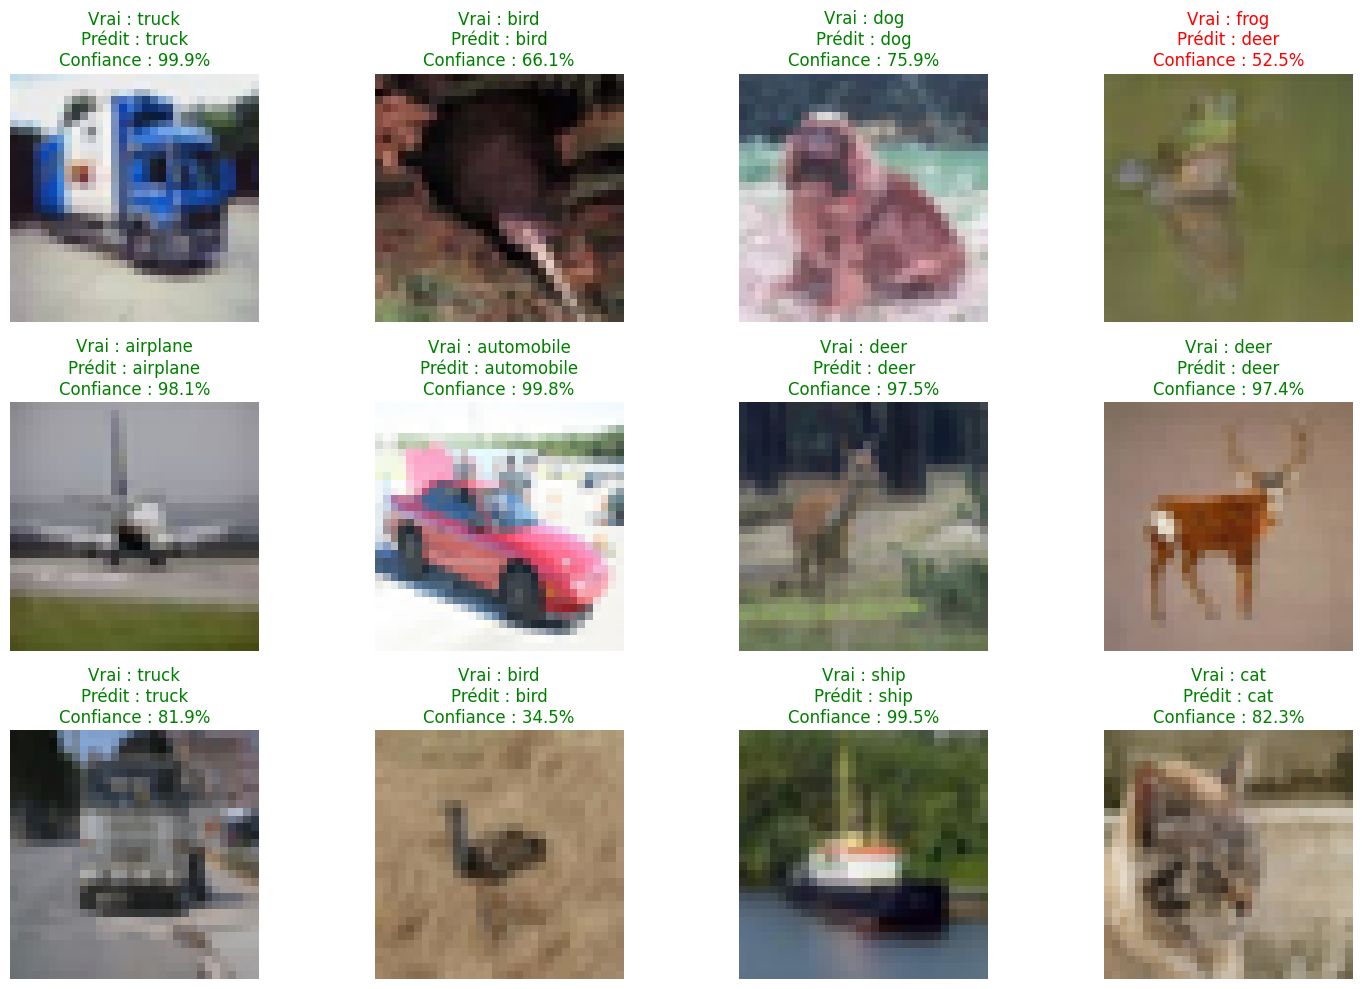

In [23]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Sélectionner 12 images du jeu de test
num_images = 12
indices = np.random.choice(len(X_test), num_images, replace=False)

images = X_test[indices]
true_labels = np.argmax(y_test[indices], axis=1)

# 2. Prédire les probabilités pour chaque classe
predictions = model_cnn_c.predict(images, verbose=0)

# 3. Récupérer la classe prédite et sa probabilité
predicted_labels = np.argmax(predictions, axis=1)
confidence = np.max(predictions, axis=1)

# 4. Afficher les images et les résultats
plt.figure(figsize=(15, 10))

for i in range(num_images):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i])

    true_name = class_name[true_labels[i]]
    predicted_name = class_name[predicted_labels[i]]

    if true_labels[i] == predicted_labels[i]:
        color = "green"
    else:
        color = "red"

    plt.title(
        f"Vrai : {true_name}\n"
        f"Prédit : {predicted_name}\n"
        f"Confiance : {confidence[i]:.1%}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


## Pretrained Model ResNet50

In [24]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.resnet50 import preprocess_input

# Taille attendue par ResNet50
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Prétraitement des images
def preprocess_images(images, labels):
    # Convertir les images et revenir à l'échelle 0-255
    images = tf.cast(images, tf.float32) * 255.0

    # Redimensionner les images
    images = tf.image.resize(images, IMG_SIZE)

    # Appliquer le prétraitement ResNet50
    images = preprocess_input(images)

    # Convertir les labels en float32
    labels = tf.cast(labels, tf.float32)

    return images, labels

# Construire les datasets
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_ds = train_ds.shuffle(
    buffer_size=10000,
    seed=42
)

train_ds = train_ds.map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

# Préparer les données de test
test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_ds = test_ds.map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

print("Pipeline d'entraînement :", train_ds)
print("Pipeline de test :", test_ds)

Pipeline d'entraînement : <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10), dtype=tf.float32, name=None))>
Pipeline de test : <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10), dtype=tf.float32, name=None))>


In [25]:

print("Forme du lot d'images :", images_batch.shape)
print("Forme du lot de labels :", labels_batch.shape)

print("Minimum des pixels après prétraitement :",
      tf.reduce_min(images_batch).numpy())

print("Maximum des pixels après prétraitement :",
      tf.reduce_max(images_batch).numpy())

print("Type des images :", images_batch.dtype)
print("Type des labels :", labels_batch.dtype)

Forme du lot d'images : (10000, 32, 32, 3)
Forme du lot de labels : (10000,)
Minimum des pixels après prétraitement : 0
Maximum des pixels après prétraitement : 255
Type des images : uint8
Type des labels : int64


## Construire ResNet50

In [26]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50

# 1. Charger ResNet50 préentraîné sur ImageNet
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# 2. Geler les poids de la base préentraînée
base_model.trainable = False

# 3. Définir la forme des images d'entrée
inputs = keras.Input(shape=(224, 224, 3))

# 4. Extraire les caractéristiques
x = base_model(inputs, training=False)

# 5. Réduire les cartes de caractéristiques
x = layers.GlobalAveragePooling2D()(x)

# 6. Ajouter notre classificateur CIFAR-10
outputs = layers.Dense(
    10,
    activation="softmax"
)(x)

# 7. Créer le modèle complet
model_resnet = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_CIFAR10"
)

# 8. Afficher le résumé
model_resnet.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ResNet50_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,608,202 (90.06 MB)

 Trainable params: 20,490 (80.04 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [27]:
model_resnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [28]:
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))

val_ds = val_ds.map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Données d'entraînement :", train_ds.element_spec)
print("Données de validation :", val_ds.element_spec)

Données d'entraînement : (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10), dtype=tf.float32, name=None))
Données de validation : (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10), dtype=tf.float32, name=None))


In [29]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = keras.callbacks.ModelCheckpoint(
    "../models/resnet50/best_resnet50.keras",
    monitor="val_loss",
    save_best_only=True
)

In [30]:
history_resnet = model_resnet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 178s 111ms/step - accuracy: 0.8651 - loss: 0.3897 - val_accuracy: 0.8924 - val_loss: 0.3070
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 146s 104ms/step - accuracy: 0.9067 - loss: 0.2658 - val_accuracy: 0.8994 - val_loss: 0.2869
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 153s 109ms/step - accuracy: 0.9203 - loss: 0.2298 - val_accuracy: 0.9066 - val_loss: 0.2834
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 146s 104ms/step - accuracy: 0.9271 - loss: 0.2093 - val_accuracy: 0.9050 - val_loss: 0.2938
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 151s 108ms/step - accuracy: 0.9322 - loss: 0.1915 - val_accuracy: 0.9046 - val_loss: 0.2864
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 203s 108ms/step - accuracy: 0.9364 - loss: 0.1791 - val_accuracy: 0.9036 - val_loss: 0.3101


In [31]:
#Identifier la meilleure époque
import numpy as np

best_epoch = np.argmin(history_resnet.history["val_loss"]) + 1
best_val_loss = min(history_resnet.history["val_loss"])
best_val_accuracy = history_resnet.history["val_accuracy"][best_epoch - 1]

print("Meilleure époque :", best_epoch)
print(f"Meilleure val_loss : {best_val_loss:.4f}")
print(f"Accuracy de validation à cette époque : {best_val_accuracy:.2%}")

Meilleure époque : 3
Meilleure val_loss : 0.2834
Accuracy de validation à cette époque : 90.66%


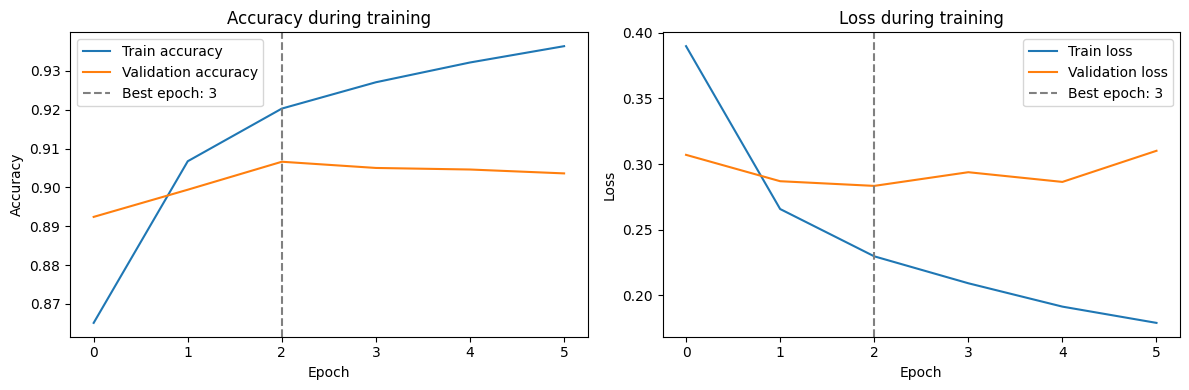

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_resnet.history["accuracy"], label="Train accuracy")
plt.plot(history_resnet.history["val_accuracy"], label="Validation accuracy")
plt.axvline(2, color="gray", linestyle="--", label="Best epoch: 3")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_resnet.history["loss"], label="Train loss")
plt.plot(history_resnet.history["val_loss"], label="Validation loss")
plt.axvline(2, color="gray", linestyle="--", label="Best epoch: 3")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.legend()

plt.tight_layout()
plt.show()

## Evaluer ResNet50 sur le jeu de Test

In [36]:
# Évaluation finale sur les données de test
test_loss, test_accuracy = model_resnet.evaluate(test_ds)

print(f"Test loss : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.2%}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - accuracy: 0.9017 - loss: 0.3048
Test loss : 0.3048
Test accuracy : 90.17%


313/313 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step


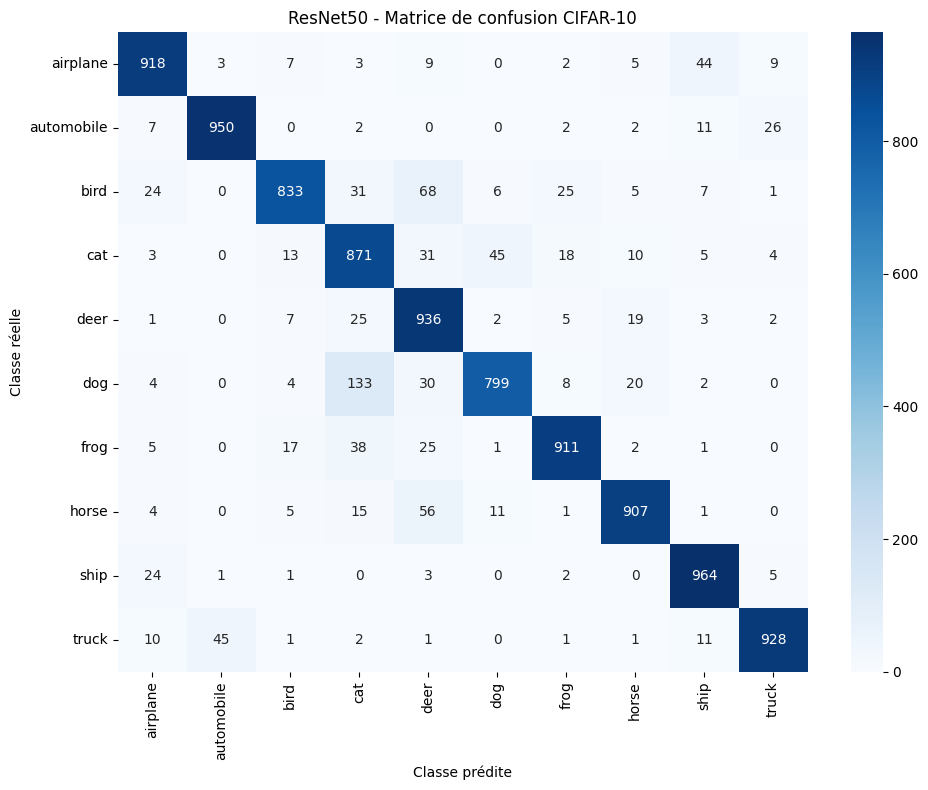

              precision    recall  f1-score   support

    airplane     0.9180    0.9180    0.9180      1000
  automobile     0.9510    0.9500    0.9505      1000
        bird     0.9381    0.8330    0.8824      1000
         cat     0.7777    0.8710    0.8217      1000
        deer     0.8076    0.9360    0.8671      1000
         dog     0.9248    0.7990    0.8573      1000
        frog     0.9344    0.9110    0.9225      1000
       horse     0.9341    0.9070    0.9203      1000
        ship     0.9190    0.9640    0.9409      1000
       truck     0.9518    0.9280    0.9397      1000

    accuracy                         0.9017     10000
   macro avg     0.9056    0.9017    0.9021     10000
weighted avg     0.9056    0.9017    0.9021     10000



In [37]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Prédictions sur le jeu de test
y_pred_proba = model_resnet.predict(test_ds)
y_pred = np.argmax(y_pred_proba, axis=1)

# Transformer les labels one-hot en numéros de classe
y_true = np.argmax(y_test, axis=1)

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("ResNet50 - Matrice de confusion CIFAR-10")
plt.tight_layout()
plt.show()

# Résultats détaillés par classe
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

In [38]:
# Sauvegarder le modèle ResNet50 entraîné
model_resnet.save("../models/resnet50/resnet50_cifar10.keras")

print("Modèle ResNet50 sauvegardé avec succès !")

Modèle ResNet50 sauvegardé avec succès !


In [39]:
from tensorflow import keras

model_resnet_loaded = keras.models.load_model(
    "../models/resnet50/resnet50_cifar10.keras"
)

print("Modèle rechargé avec succès !")
print("Nom :", model_resnet_loaded.name)
print("Nombre de paramètres :", model_resnet_loaded.count_params())

Modèle rechargé avec succès !
Nom : ResNet50_CIFAR10
Nombre de paramètres : 23608202


,Model,Test Accuracy (%)
0,ResNet50,90.17
1,CNN C,81.91
2,CNN B,77.33
3,CNN A,72.26
4,MLP,43.36


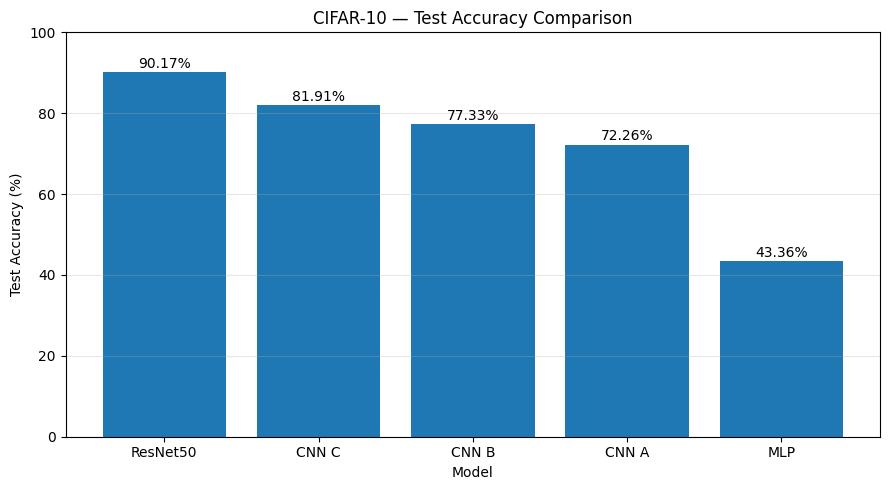

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Model": ["MLP", "CNN A", "CNN B", "CNN C", "ResNet50"],
    "Test Accuracy (%)": [43.36, 72.26, 77.33, 81.91, 90.17]
})

results = results.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(results)

plt.figure(figsize=(9, 5))
bars = plt.bar(
    results["Model"],
    results["Test Accuracy (%)"]
)

plt.title("CIFAR-10 — Test Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, results["Test Accuracy (%)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("../results/figures/comparison/model_comparison.png", dpi=200)
plt.show()

In [100]:
import os

model_paths = {
    "MLP": "../models/mlp/model_mlp.keras",
    "CNN A": "../models/cnn_a/cnn_a_cifar10.keras",
    "CNN B": "../models/cnn_b/cnn_bifar10.keras",
    "CNN C": "../models/cnn_c/cnn_cifar10.keras",
    "ResNet50": "../models/resnet50/resnet50_cifar10.keras",
}

for name, path in model_paths.items():
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024**2)
        print(f"✅ {name}: disponible ({size_mb:.1f} MB)")
    else:
        print(f"❌ {name}: fichier introuvable — {path}")

✅ MLP: disponible (4.5 MB)
✅ CNN A: disponible (6.3 MB)
✅ CNN B: disponible (4.7 MB)
✅ CNN C: disponible (4.7 MB)
✅ ResNet50: disponible (90.8 MB)


## créer l'application Streamlit

In [41]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 22.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 66.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [67]:
import os

model_path = "../models/resnet50/resnet50_cifar10.keras"

print("Modèle disponible :", os.path.exists(model_path))

Modèle disponible : True


In [43]:
!pip install -q streamlit

In [68]:
import os

MODEL_PATH = "../models/resnet50/resnet50_cifar10.keras"

if os.path.exists(MODEL_PATH):
    print("✅ Modèle ResNet50 trouvé")
    print(f"Taille : {os.path.getsize(MODEL_PATH) / (1024**2):.1f} MB")
else:
    print("❌ Modèle introuvable : il faut le recharger dans Colab")

✅ Modèle ResNet50 trouvé
Taille : 90.8 MB


In [69]:
%%writefile ../app/app.py

import time
from pathlib import Path

import numpy as np
import streamlit as st
import tensorflow as tf

from PIL import Image
from tensorflow import keras
from tensorflow.keras.applications.resnet50 import preprocess_input


# =====================================================
# 1. Configuration
# =====================================================

st.set_page_config(
    page_title="CIFAR-10 Model Studio",
    page_icon="🧠",
    layout="wide"
)

CLASS_NAMES = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

BASE_DIR = Path(__file__).resolve().parent.parent

MODEL_PATHS = {
    "MLP": str(BASE_DIR / "models/mlp/model_mlp.keras"),
    "CNN A": str(BASE_DIR / "models/cnn_a/cnn_a_cifar10.keras"),
    "CNN B": str(BASE_DIR / "models/cnn_b/cnn_bifar10.keras"),
    "CNN C": str(BASE_DIR / "models/cnn_c/cnn_cifar10.keras"),
    "ResNet50": str(BASE_DIR / "models/resnet50/resnet50_cifar10.keras"),
}

# Résultats de test mesurés précédemment.
# Ils servent de référence, pas de garantie pour une image donnée.
BENCHMARK_ACCURACY = {
    "MLP": 43.36,
    "CNN A": 72.26,
    "CNN B": 77.33,
    "CNN C": 81.91,
    "ResNet50": 90.17,
}


# =====================================================
# 2. Charger les modèles une seule fois
# =====================================================

@st.cache_resource
def load_all_models():
    loaded = {}

    for name, path in MODEL_PATHS.items():
        loaded[name] = keras.models.load_model(path)

    return loaded


# =====================================================
# 3. Prétraiter une image selon le modèle
# =====================================================

def prepare_image(image, model_name):
    if model_name == "ResNet50":
        image = image.resize((224, 224))
        array = np.asarray(image, dtype=np.float32)
        array = np.expand_dims(array, axis=0)
        return preprocess_input(array)

    # MLP et CNN : images 32 x 32, valeurs entre 0 et 1
    image = image.resize((32, 32))
    array = np.asarray(image, dtype=np.float32) / 255.0
    array = np.expand_dims(array, axis=0)

    return array


# =====================================================
# 4. Faire une prédiction
# =====================================================

def predict_image(model, image, model_name):
    input_array = prepare_image(image, model_name)

    start = time.perf_counter()

    probabilities = model.predict(
        input_array,
        verbose=0
    )[0]

    elapsed = (time.perf_counter() - start) * 1000

    predicted_index = int(np.argmax(probabilities))

    return {
        "class": CLASS_NAMES[predicted_index],
        "confidence": float(probabilities[predicted_index]),
        "probabilities": probabilities,
        "time_ms": elapsed,
    }


# =====================================================
# 5. Interface
# =====================================================

st.title("🧠 CIFAR-10 Model Studio")

st.write(
    "Compare five trained deep learning models "
    "for image classification."
)

st.info(
    "The app reuses saved models. No training is performed."
)

# Charger les modèles
try:
    models = load_all_models()
    st.success("All five models loaded successfully.")
except Exception as error:
    st.error(f"Unable to load the models: {error}")
    st.stop()


# Choix du mode
mode = st.radio(
    "Prediction mode",
    [
        "Recommended model",
        "Choose a model",
        "Compare all five models",
    ],
    horizontal=True
)

# Choix de l'image
uploaded_file = st.file_uploader(
    "Upload an image",
    type=["png", "jpg", "jpeg"]
)

if uploaded_file is not None:
    try:
        image = Image.open(uploaded_file).convert("RGB")

        st.subheader("Uploaded image")
        st.image(image, caption="Input image", width=300)

        if st.button("Run prediction", type="primary"):

            if mode == "Recommended model":
                selected_models = ["ResNet50"]

            elif mode == "Choose a model":
                selected = st.selectbox(
                    "Select the model",
                    list(MODEL_PATHS.keys())
                )
                selected_models = [selected]

            else:
                selected_models = list(MODEL_PATHS.keys())

            results = {}

            with st.spinner("Running predictions..."):
                for name in selected_models:
                    results[name] = predict_image(
                        models[name],
                        image,
                        name
                    )

            # Afficher les prédictions
            st.subheader("Prediction results")

            columns = st.columns(len(results))

            for column, (name, result) in zip(
                columns, results.items()
            ):
                with column:
                    st.markdown(f"### {name}")
                    st.metric(
                        "Predicted class",
                        result["class"]
                    )
                    st.metric(
                        "Confidence",
                        f'{result["confidence"]:.2%}'
                    )
                    st.caption(
                        f'Inference time: {result["time_ms"]:.1f} ms'
                    )

            # Probabilités détaillées
            st.subheader("Class probabilities")

            probability_data = {}

            for name, result in results.items():
                probability_data[name] = result["probabilities"]

            import pandas as pd

            probability_df = pd.DataFrame(
                probability_data,
                index=CLASS_NAMES
            )

            st.bar_chart(probability_df)

            # Référence des performances précédentes
            st.subheader("Previously measured test accuracy")

            benchmark_df = pd.DataFrame({
                "Model": list(BENCHMARK_ACCURACY.keys()),
                "Test accuracy (%)": list(
                    BENCHMARK_ACCURACY.values()
                )
            }).set_index("Model")

            st.bar_chart(benchmark_df)

            st.caption(
                "Benchmark accuracy comes from previous evaluations "
                "on CIFAR-10. It does not guarantee that a model "
                "will predict every individual image correctly. "
                "Confidence scores are not necessarily calibrated."
            )

    except Exception as error:
        st.error(f"Error processing the image: {error}")

Writing /content/app.py


In [82]:
import os

print("app.py existe :", os.path.exists("../app/app.py"))

app.py existe : True


In [90]:
!streamlit run ../app/app.py --server.port 8501 --server.headless true > streamlit.log 2>&1 &

In [93]:
import os
import subprocess
import time

# Vider l'ancien journal
open("streamlit.log", "w").close()

# Relancer Streamlit en arrière-plan
log = open("streamlit.log", "w")
process = subprocess.Popen(
    [
        "streamlit", "run", "../app/app.py",
        "--server.port", "8501",
        "--server.headless", "true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("PID du nouveau processus :", process.pid)

with open("streamlit.log", "r") as f:
    print(f.read()[-3000:])

PID du nouveau processus : 40675


2026-10-23 22:06:08.898 Port 8501 is not available



In [94]:
!ps aux | grep '[s]treamlit'

root       39153  1.1  0.5 452124 72224 ?        Ssl  22:00   0:04 /usr/bin/python3 /usr/local/bin/streamlit run /content/app.py --server.port 8501 --server.headless true
root       40675  8.4  0.0      0     0 ?        Zs   22:06   0:02 [streamlit] <defunct>


In [95]:
import os
import signal

pid = 39153

try:
    os.kill(pid, signal.SIGTERM)
    print(f"Signal d'arrêt envoyé au processus {pid}.")
except ProcessLookupError:
    print("Le processus est déjà arrêté.")

Signal d'arrêt envoyé au processus 39153.


In [96]:
!ps -p 39153 -o pid,stat,cmd

    PID STAT CMD


In [97]:
import subprocess
import time

with open("streamlit.log", "w") as log:
    process = subprocess.Popen(
        [
            "streamlit", "run", "../app/app.py",
            "--server.port", "8501",
            "--server.headless", "true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

time.sleep(5)

with open("streamlit.log", "r") as f:
    print(f.read()[-3000:])



2026-10-23 22:08:26.953 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.125.208.232:8501




In [103]:
public_url = ngrok.connect(8501)
print("Lien de l'application :", public_url)

Lien de l'application : NgrokTunnel: "https://pager-earthworm-snowfall.ngrok-free.dev" -> "http://localhost:8501"


In [104]:
from google.colab import files

files.download("../app/app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>